# 錯誤更正碼 1116

1109 講義介紹了 peeling、stopping sets、Tanner graph，  
也在高維 product codes 上做了 density evolution：  
每個方向解一次時，乘積結構保證了獨立性，遞迴是精確的。  
今天放棄乘積結構，改用隨機的 sparse Tanner graph，  
也就是 LDPC codes，5G、Wi-Fi、衛星電視、SSD 都在用。

食譜
- LDPC code：Tanner graph 中每個 bit 只連到少數 checks。
- Density evolution：用樹取代乘積結構，在 BEC 上算出 threshold。
- Bit flipping：翻轉所在的 unsatisfied checks 最多的 bit。
- Belief propagation：0929 週一作業的 bias update 就是 BP。

## LDPC Codes

### LDPC codes

**定義：** 若 Tanner graph 的每個 VN 的 degree 都是 $d_v$，  
每個 CN 的 degree 都是 $d_c$，  
就稱 $\mathcal C$（或 $H$）是 **$(d_v, d_c)$-regular**。  
$d_v, d_c$ 固定而 $n \to \infty$ 時，$H$ 只有 $nd_v$ 個 $1$，  
和 $H$ 的 entries 個數相比非常少。  
這類 codes 稱為 **LDPC（low-density parity-check）codes**。

Gallager 在 1960 年代初的博士論文中提出 LDPC codes，  
但當時的電腦算不動，這些 codes 被遺忘了三十年。  
1993 年 turbo codes 出現後，  
MacKay 與 Neal 在 1990 年代中期重新發現它們，  
發現它們和 turbo codes 一樣非常接近理論極限。

數邊：$nd_v = rd_c$，所以 $r = nd_v/d_c$。  
$\operatorname{rank} H \le r$，所以
$$\frac kn \ge 1 - \frac{d_v}{d_c}.$$
$H$ 的 columns 線性相依時，例如 1109 講義的 check on checks，  
rate 會比這個下界大。

$[n, n - 1, 2]^{\otimes2}$ 是 $(2, n)$-regular，下界是 $1 - 2/n$，  
真正的 rate $(1 - 1/n)^2$ 多出的 $1/n^2$ 就來自 check on checks。

### BCH 的 checks 都很重

1102 講義的 BCH codes 也可以畫 Tanner graph，  
但 dual code 中沒有輕的 codewords，也就找不到 sparse 的 $H$。  
下面計算 designed distance $5$ 的 BCH codes 的 dual code 中，  
最輕的非零 codeword 的 weight。

In [1]:
for n in [31, 63, 127]:
    D = codes.BCHCode(GF(2), n, 5).dual_code()
    print(n, D.dimension(), min(c.hamming_weight() for c in D if c != 0))

31 10 12
63 12 24
127 14 56


最輕的 check 都接近 $n/2$。  
每個 check 包含一半的 bits，  
任兩個 bits 幾乎一定同時出現在許多 checks 中，  
Tanner graph 到處是長度 $4$ 的 cycles。  
後面會看到，cycles 正是 message passing 的敵人。

### 隨機的 regular LDPC codes

怎麼造一個 $(d_v, d_c)$-regular 的 $H$？  
給每個 VN $d_v$ 個插座，每個 CN $d_c$ 個插座，  
兩邊都有 $nd_v = rd_c$ 個，再用一個隨機排列把兩邊的插座配對。  
若同一個 check 連到同一個 bit 兩次，  
在 $\mathbb F_2$ 中會抵消，這裡直接重抽。

`checks` 的第 $j$ 個 row 列出第 $j$ 個 check 包含的 bits。

SageMath 把程式中的整數常數換成自己的 `Integer`，  
numpy 的 random generator 需要 Python 的 `int`，  
所以 seed 寫成 `int(1145)`。

In [2]:
import numpy as np

rng = np.random.default_rng(int(1145))

In [3]:
def random_regular_ldpc(n, dv, dc):
    while True:
        checks = rng.permutation(np.repeat(np.arange(n), dv)).reshape(-1, dc)
        if all(len(set(ch)) == dc for ch in checks):
            return checks

In [4]:
print(random_regular_ldpc(12, 3, 6))

[[ 8  7  9  4  2  3]
 [10  0 11  1  6  9]
 [ 0 11  1  8  2  5]
 [ 9 10  8  3  0 11]
 [ 6  5  7  2  3  4]
 [ 7 10  4  1  6  5]]


接著造一個長度 $1{,}000$ 的 $(3, 6)$-regular code，  
算出 $H$ 的 rank 與 dimension。

In [5]:
def check_matrix(checks, n):
    return matrix(GF(2), n, len(checks), {(int(i), j): 1 for j, ch in enumerate(checks) for i in ch})

H = check_matrix(random_regular_ldpc(1000, 3, 6), 1000)
print(H.dimensions(), H.rank(), 1000 - H.rank())

(1000, 500) 500 500


### 為什麼 $d_v \ge 3$

Gallager 證明：$d_v \ge 3$ 時，  
隨機的 $(d_v, d_c)$-regular code 以很高的機率有 $d \ge \delta n$，  
其中 $\delta > 0$ 只和 $d_v, d_c$ 有關。  
$d_v = 2$ 則不行，論證和 1109 講義的 product code 一樣。

$d_v = 2$ 時每個 bit 恰好在兩個 checks 中。  
把 checks 當作 vertices，  
每個 bit 當作連接它的兩個 checks 的邊，  
codeword 就是每個 vertex 都連到偶數條邊的邊集合，  
所以每個 cycle 都是 codeword。

這張圖有 $r$ 個 vertices，每個的 degree 都是 $d_c$。  
若最短 cycle 的長度是 $g$，  
從一個 vertex 出發、距離小於 $g/2$ 的部分是一棵樹，  
至少有 $(d_c - 1)^{\lfloor(g-1)/2\rfloor}$ 個 vertices，  
所以 $g \le 2\log_{d_c-1} r + 2$。  
因此 $d \le g$ 只隨 $\log n$ 成長，相對距離 $d/n \to 0$。

## Density Evolution

### 把 peeling 寫成 message passing

Peeling 一次只補一個 bit。  
平行的版本是在 Tanner graph 的每條邊上  
同時傳遞訊息「已知」或「$\mathrm e$」，每一輪兩個方向各傳一次：
- VN $v$ 告訴 CN $c$「已知」，  
  若 $v$ 沒被擦除，或除了 $c$ 以外的某個 check 告訴 $v$「已知」。
- CN $c$ 告訴 VN $v$「已知」，  
  若除了 $v$ 以外的 $d_c - 1$ 個鄰居都告訴 $c$「已知」。

送給某個鄰居的訊息不使用那個鄰居送來的訊息，  
這叫做 **extrinsic** information，  
就像 0929 週一作業用「另外 $7$ 個 coordinates」計算 $\gamma_i$。  
和 1109 講義的 peeling 一樣，這個平行版本最後剩下的 $\mathrm e$  
也是 $E$ 所包含的最大 stopping set。

### 遞迴

令 $x_\ell$ 是第 $\ell$ 輪 VN 送出「$\mathrm e$」的機率，$x_0 = \epsilon$。  
這裡沒有 1109 講義的乘積結構保證獨立，只能假設：  
VN 周圍 $2\ell$ 步以內的 Tanner graph 是一棵樹，  
那麼送進同一個 node 的訊息來自不相交的子樹，彼此獨立。  
CN 送出「$\mathrm e$」，  
若其他 $d_c - 1$ 個鄰居中至少有一個送來「$\mathrm e$」，  
機率是 $1 - (1 - x_\ell)^{d_c-1}$。

VN 送出「$\mathrm e$」，  
若它被擦除，而且其他 $d_v - 1$ 個 checks 都送來「$\mathrm e$」：
$$x_{\ell+1} = \epsilon\bigl(1 - (1 - x_\ell)^{d_c-1}\bigr)^{d_v-1}.$$

這個遞迴稱為 **density evolution**（Richardson–Urbanke 2001）。  
對隨機的 regular LDPC code，固定 $\ell$ 而 $n \to \infty$ 時，  
周圍 $2\ell$ 步以內不是樹的 VNs 所佔的比例趨近 $0$，  
所以 $x_\ell$ 準確描述長的隨機 codes 在第 $\ell$ 輪的行為。

### Threshold

令 $f(x) = \epsilon\bigl(1 - (1 - x)^{d_c-1}\bigr)^{d_v-1}$，它是 $x$ 的遞增函數。  
$x_1 = f(\epsilon) \le \epsilon = x_0$，  
再用歸納法，$x_{\ell+1} = f(x_\ell) \le f(x_{\ell-1}) = x_\ell$。  
所以 $x_\ell$ 遞減，收斂到 $f$ 在 $[0, \epsilon]$ 中最大的不動點。  
$x_\ell \to 0$ 當且僅當 $f(x) < x$ 對所有 $x \in (0, \epsilon]$ 成立。

$x > \epsilon$ 時 $f(x) \le \epsilon < x$ 自動成立，所以條件可以寫成
$$\epsilon < \frac{x}{\bigl(1 - (1 - x)^{d_c-1}\bigr)^{d_v-1}}
\qquad\text{for all }0 < x \le 1.$$

右邊的下確界稱為 **threshold**：
$$\epsilon^*
= \inf_{0<x\le1}\frac{x}{\bigl(1 - (1 - x)^{d_c-1}\bigr)^{d_v-1}}.$$
$\epsilon < \epsilon^*$ 時 $x_\ell \to 0$，幾乎所有 bits 都補得回來；  
$\epsilon > \epsilon^*$ 時 $x_\ell$ 停在正的不動點，  
有固定比例的 bits 補不回來。

$d_v = 2$ 時，$1 - (1 - x)^{d_c-1}$ 是凹函數而且在 $x = 0$ 為 $0$，  
所以 $\frac{x}{1 - (1 - x)^{d_c-1}}$ 遞增，下確界在 $x \to 0$ 取到：
$$\epsilon^* = \lim_{x\to0}\frac{x}{1 - (1 - x)^{d_c-1}} = \frac1{d_c - 1}.$$
$d_v \ge 3$ 時，下確界要用數值計算。

In [6]:
x = var("x")

def threshold(dv, dc):
    return find_local_minimum(x / (1 - (1 - x)**(dc - 1))**(dv - 1), 1e-9, 1)[0]

In [7]:
for dv, dc in [(2, 4), (3, 6), (4, 8), (5, 10), (3, 4), (3, 5)]:
    print((dv, dc), 1 - dv / dc, round(threshold(dv, dc), 4))

(2, 4) 1/2 0.3333
(3, 6) 1/2 0.4294
(4, 8) 1/2 0.3834
(5, 10) 1/2 0.3416
(3, 4) 1/4 0.6474
(3, 5) 2/5 0.5176


下圖把 $(3, 6)$ 的 $f(x)$ 畫在對角線 $y = x$ 旁邊。  
遞迴 $x_{\ell+1} = f(x_\ell)$ 就是在曲線與對角線之間走階梯。  
$\epsilon = 0.40$ 時曲線一路在對角線下方，階梯走到 $0$；  
$\epsilon = 0.45$ 時曲線碰到對角線，階梯卡在交點。

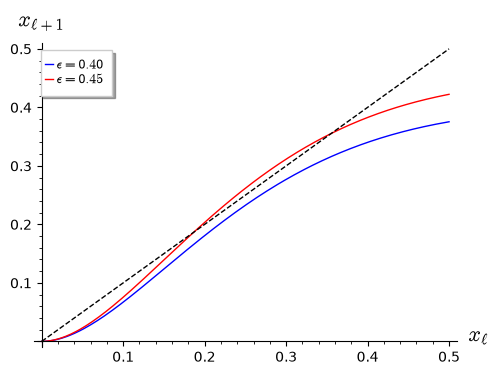

In [8]:
f = lambda eps, x: eps * (1 - (1 - x)**5)**2
(plot(f(0.40, x), (x, 0, 0.5), legend_label=r"$\epsilon = 0.40$")
 + plot(f(0.45, x), (x, 0, 0.5), color="red", legend_label=r"$\epsilon = 0.45$")
 + plot(x, (x, 0, 0.5), color="black", linestyle="--")
 ).show(axes_labels=[r"$x_\ell$", r"$x_{\ell+1}$"], figsize=5)

In [9]:
for eps in [0.40, 0.45]:
    xl = eps
    for _ in range(1000):
        xl = f(eps, xl)
    print(eps, xl)

0.400000000000000 0.000000000000000
0.450000000000000 0.355443307748107


### 和 capacity 比較

沿用 row-vector 慣例 $c = uG$。  
收到的 bits 中沒被擦除的位置記為 $\bar E$，  
它們決定 $u$ 當且僅當 $G$ 在 $\bar E$ 上的 columns 的 rank 是 $k$，  
所以至少要有 $k$ 個 bits 沒被擦除：$k \le n - |E|$。  
$|E|$ 約為 $\epsilon n$，  
所以 rate $R = k/n$ 的 code 要可靠地解碼，必須 $R \le 1 - \epsilon$。

Shannon 的 channel coding theorem 說這個上界可以逼近：  
$\operatorname{BEC}(\epsilon)$ 的 **capacity** 是 $1 - \epsilon$，  
rate 小於 $1 - \epsilon$ 時，存在 block error probability 趨近 $0$ 的 codes。

所以 rate $1/2$ 的 codes 最多能承受 $\epsilon = 0.5$。  
上表中 $(3, 6)$ 的 threshold $0.4294$ 是 regular codes 中最好的；  
$d_v$ 再大，每個 bit 雖然有更多 checks 幫忙，  
但每個 check 也更重，更容易包含 $\mathrm e$。  
要更接近 $0.5$，需要讓 degrees 不全相同，見延伸話題。

### 模擬

長的 codes 改用 numpy 寫平行的版本：  
`erased` 是長度 $n$ 的 boolean array，  
`erased[checks]` 標出每個 check 的哪些 bits 被擦除。  
每一輪找出恰好剩一個 $\mathrm e$ 的 checks，同時補回它們的 $\mathrm e$。

In [10]:
def peel_ldpc(checks, erased):
    while True:
        rows = checks[erased[checks].sum(axis=1) == 1]
        if rows.size == 0:
            return erased
        erased[rows[erased[rows]]] = False

對長度 $500$ 與 $4{,}000$ 的隨機 $(3, 6)$ codes，  
每個 $\epsilon$ 模擬 $100$ 個 blocks，只要有 $\mathrm e$ 沒補回就算 block error。  
輸出依序列出各個 $\epsilon$ 的 block errors 個數。  
Linear code 在 BEC 上能否補回只和 erasures 的位置有關，  
所以不需要真的 encode。  
虛線是 threshold $0.4294$ 與 capacity $0.5$。

In [11]:
bec_codes = {n: random_regular_ldpc(n, 3, 6) for n in [500, 4000]}

In [12]:
eps_list = np.arange(0.30, 0.505, 0.01)
curves = {}
for n, checks_n in bec_codes.items():
    fails = [sum(peel_ldpc(checks_n, rng.random(n) < eps).any() for _ in range(100)) for eps in eps_list]
    print(n, fails)
    curves[n] = [(float(eps), f / 100) for eps, f in zip(eps_list, fails)]

500 [12, 15, 13, 13, 11, 10, 13, 21, 23, 28, 27, 44, 64, 79, 81, 90, 96, 99, 99, 100, 100]


4000 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 19, 64, 91, 99, 100, 100, 100, 100, 100]


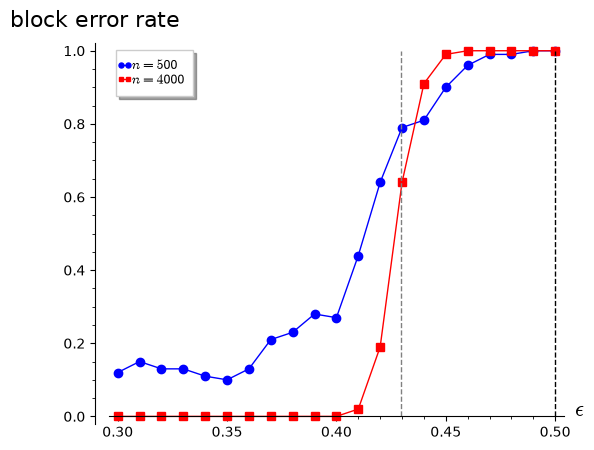

In [13]:
(line(curves[500], marker="o", legend_label=r"$n = 500$")
 + line(curves[4000], marker="s", color="red", legend_label=r"$n = 4000$")
 + line([(0.4294, 0), (0.4294, 1)], color="gray", linestyle="--")
 + line([(0.5, 0), (0.5, 1)], color="black", linestyle="--")
 ).show(axes_labels=[r"$\epsilon$", "block error rate"], figsize=6)

$n$ 越大，曲線越陡，越接近在 $\epsilon^*$ 處從 $0$ 跳到 $1$ 的階梯。  
但 $n = 500$ 的曲線在 $\epsilon = 0.3$ 就有約 $10\%$ 的 block errors，  
而且幾乎不隨 $\epsilon$ 變小。  
下面找出原因：$H$ 中有沒有兩個完全相同的 rows？

In [14]:
H500 = check_matrix(bec_codes[500], 500)
same = {}
for i, row in enumerate(H500.rows()):
    same.setdefault(tuple(row.support()), []).append(i)
print([(bits, nbrs) for nbrs, bits in same.items() if len(bits) > 1])

[([209, 496], (96, 98, 230))]


這兩個 bits 連到完全相同的三個 checks。  
它們同時被擦除的機率是 $\epsilon^2$，此時沒有任何 check 只含一個 $\mathrm e$：  
這是大小 $2$ 的 stopping set，  
也是一個 weight 為 $2$ 的 codeword，任何 decoder 都救不了。  
所以這個 code 的 block error rate 至少是 $\epsilon^2$，  
$\epsilon = 0.3$ 時就是 $0.09$。

隨機構造的 codes 偶爾會有這種很小的 stopping sets，  
$n$ 越小越容易碰到。  
實際使用的 LDPC codes 會檢查並避開它們，  
例如要求 Tanner graph 的 girth 夠大。

## Bit-Flipping Decoding

### 數不滿足的 checks

在 $\operatorname{BSC}(p)$ 上沒有 erasures，而是有些 bits 被翻轉，  
decoder 不知道是哪些。  
收到 $y$ 後計算每個 check：加起來是 $1$ 的 check 稱為 **unsatisfied**。  
Gallager 的 **bit-flipping** decoder 重複下列步驟，  
直到所有 checks 都滿足：  
找出所在的 unsatisfied checks 最多的 bit，翻轉它。

例如 1109 講義的 $[9, 4, 4]$ 中間的 bit $(2, 2)$ 被翻轉：  
row $2$ 與 column $2$ 變成 unsatisfied。  
Bit $(2, 2)$ 的兩個 checks 都 unsatisfied，  
同一個 row 或 column 的其他 bits 只有一個 unsatisfied check，  
其餘 bits 沒有，所以 decoder 翻回 bit $(2, 2)$。

翻轉 bit 寫成 `x[i] = 1 - x[i]`。  
`unsat` 列出 unsatisfied checks，  
`np.bincount` 數出每個 bit 在其中出現幾次。

In [15]:
def bit_flip(checks, y):
    x = y.copy()
    for _ in range(len(y)):
        unsat = checks[x[checks].sum(axis=1) % 2 == 1]
        if unsat.size == 0:
            break
        i = np.bincount(unsat.ravel(), minlength=len(x)).argmax()
        x[i] = 1 - x[i]
    return x

Bit flipping 只用到 hard decisions，  
而且每個 check 只回報「滿足或不滿足」。  
下一節的 belief propagation 讓每個 check 回報更細的資訊：  
它認為每個 bit 是 $0$ 的可能性有多大。

## Belief Propagation

### 回顧 0929 週一作業

0929 週一作業用 spin $\sigma = (-1)^x$ 表示 bit $x$，並用 bias
$$\beta = \Pr(\sigma = +1 \mid y) - \Pr(\sigma = -1 \mid y)
= \mathbb E[\sigma \mid y]$$
記錄接收端對這個 bit 的信心。  
作業中的兩個公式，正好是 belief propagation 的兩種 nodes。

**CN：** parity check 的 support 是 $S$，  
則 $\sum_{j\in S} x_j = 0$，也就是 $\prod_{j\in S}\sigma_j = 1$。  
因此 $\sigma_i = \prod_{j\in S\setminus\{i\}}\sigma_j$。  
若其他 bits 的資訊互相獨立，biases 分別是 $\beta_j$，則
$$\mathbb E[\sigma_i]
= \prod_{j\in S\setminus\{i\}}\mathbb E[\sigma_j]
= \prod_{j\in S\setminus\{i\}}\beta_j
= \gamma_i.$$

**VN：** 對同一個 $\sigma$ 有兩份獨立的資訊，  
biases 分別是 $\beta$ 與 $\gamma$。  
在 $\sigma$ 均勻分布的假設下，$\Pr(\sigma = s \mid y) = (1 + s\beta)/2$，  
所以 likelihood 正比於 $1 + s\beta$。  
兩份獨立資訊的 likelihoods 相乘，  
posterior 正比於 $(1 + s\beta)(1 + s\gamma)$。

所以合併後的 bias 是
$$\frac{(1 + \beta)(1 + \gamma) - (1 - \beta)(1 - \gamma)}
{(1 + \beta)(1 + \gamma) + (1 - \beta)(1 - \gamma)}
= \frac{\beta + \gamma}{1 + \beta\gamma}.$$
這就是作業最後追加的「正確」update rule；  
一開始的 $\beta + (1 - |\beta|)\gamma$ 只是 heuristic。

作業的做法還有一個缺陷：$\beta_i$ 被反覆更新，  
同一份資訊會繞一圈回來，再被當成新的證據合併一次。  
Belief propagation 把訊息放在 Tanner graph 的每條邊上，  
送給某個鄰居的訊息不包含那個鄰居送來的資訊，  
也就是前面 density evolution 的 extrinsic 原則。

### Log-likelihood ratio

實作上常用 **log-likelihood ratio（LLR）**
$$L = \ln\frac{\Pr(x = 0 \mid y)}{\Pr(x = 1 \mid y)}.$$

$\Pr(x = 0 \mid y) = e^L/(1 + e^L)$，所以
$$\beta = \frac{e^L - 1}{e^L + 1} = \tanh(L/2).$$

在 LLR 下，VN 的合併就是相加：  
$\tanh$ 的和角公式
$$\tanh(a + b) = \frac{\tanh a + \tanh b}{1 + \tanh(a) \tanh(b)}$$
正是 $\frac{\beta + \gamma}{1 + \beta\gamma}$。

CN 則變成 **tanh rule**：
$$L_i = 2\operatorname{artanh}\prod_{j\in S\setminus\{i\}}\tanh(L_j/2).$$

0914 講義的三種 channels 收到 $y$ 後的 LLR：
- $\operatorname{BEC}(\epsilon)$：收到 $0$ 是 $+\infty$，收到 $1$ 是 $-\infty$，  
  收到 $\mathrm e$ 是 $0$。
- $\operatorname{BSC}(p)$：收到 $0$ 是 $\ln\frac{1 - p}{p}$，  
  收到 $1$ 是 $-\ln\frac{1 - p}{p}$。
- BPSK 經過 AWGN，$0 \mapsto +A$、$1 \mapsto -A$，  
  雜訊為 $\mathcal N(0, \sigma^2)$：$L = 2Ay/\sigma^2$。

AWGN 的 LLR 保留了 $y$ 的大小，  
這是 hard decision 丟掉的可靠度資訊。

### 在 Tanner graph 上傳遞 LLR

令 $L_v$ 是 bit $v$ 從 channel 得到的 LLR。  
每條邊在兩個方向上各有一個訊息，一開始 $m_{c\to v} = 0$。

每一輪依序計算
$$\begin{aligned}
m_{v\to c} &= L_v + \sum_{c'\ne c} m_{c'\to v}, \\
m_{c\to v} &= 2\operatorname{artanh}\prod_{v'\ne v}\tanh(m_{v'\to c}/2).
\end{aligned}$$

其中 $c'$ 跑遍 $v$ 的其他鄰居，$v'$ 跑遍 $c$ 的其他鄰居。  
每一輪結束時，bit $v$ 的總 LLR 是 $L_v + \sum_c m_{c\to v}$，  
依正負號判為 $0$ 或 $1$。  
若判出來的向量滿足所有 checks，就停止。

Tanner graph 是樹的時候，跑足夠多輪後，  
總 LLR 正是 $\ln\frac{\Pr(x_v = 0 \mid y)}{\Pr(x_v = 1 \mid y)}$；  
有 cycles 時這只是近似，  
而 girth 越大，前幾輪越接近樹的情形。

在 BEC 上，LLR 只有 $+\infty$、$-\infty$、$0$ 三種值：  
$\tanh(\pm\infty) = \pm1$，$\tanh(0) = 0$，  
所以 CN 的乘積只要有一個 $0$ 就是 $0$。  
這正是平行版本的 peeling，  
BEC 上的 density evolution 也就是 BP 的 density evolution。

下面用 numpy 實作，  
`checks` 每個 row 的 $d_c$ 個 entries 就是 $d_c$ 條邊，  
訊息也排成同樣形狀的陣列。  
`check_update` 是 tanh rule：`np.delete` 把自己從乘積中拿掉。

In [16]:
def check_update(v2c):
    t = np.tanh(v2c / 2)
    ext = np.stack([np.delete(t, i, axis=1).prod(axis=1) for i in range(t.shape[1])], axis=1)
    return 2 * np.arctanh(np.clip(ext, -1 + 1e-12, 1 - 1e-12))

`total[checks] - c2v` 從每個 bit 的總 LLR 扣掉該條邊送來的訊息，  
得到 extrinsic 的 $m_{v\to c}$。

In [17]:
def bp_decode(checks, L, iters=50):
    c2v = np.zeros(checks.shape)
    for _ in range(iters):
        total = L + np.bincount(checks.ravel(), weights=c2v.ravel(), minlength=len(L))
        x = (total < 0).astype(int)
        if not (x[checks].sum(axis=1) % 2).any():
            break
        c2v = check_update(total[checks] - c2v)
    return x

### Min-sum

每個 $|\tanh(m/2)| \le 1$，  
所以 tanh rule 的輸出的絕對值不超過輸入中最小的絕對值。  
把它近似成
$$m_{c\to v} \approx \Bigl(\prod_{v'\ne v}\operatorname{sign} m_{v'\to c}\Bigr)
\min_{v'\ne v}|m_{v'\to c}|,$$
就是 **min-sum** decoder：只需要比較大小與正負號，硬體很便宜。

Min-sum 會高估訊息的信心，  
實務上再乘上略小於 $1$ 的常數（normalized min-sum），  
或減去一個小常數（offset min-sum）。

### 模擬：BSC

和 0929 作業一樣，利用 linearity 與 BSC 的 symmetry，  
固定傳送 all-zero codeword，收到的就是 error pattern $e$。  
解出非零向量就是 block error。  
下面對長度 $1{,}000$ 的隨機 $(3, 6)$ code，  
每個 $p$ 模擬 $100$ 個 blocks，比較 bit flipping 與 BP。  
輸出的每一行是 $p$、  
bit flipping 的 block errors 個數、BP 的 block errors 個數。

In [18]:
n = 1000
checks_n = random_regular_ldpc(n, 3, 6)

In [19]:
def bsc_errors(p, trials=100):
    es = [(rng.random(n) < p).astype(int) for _ in range(trials)]
    bf = sum(bit_flip(checks_n, e).any() for e in es)
    bp = sum(bp_decode(checks_n, np.where(e == 1, -1.0, 1.0) * np.log((1 - p) / p)).any() for e in es)
    return bf, bp

In [20]:
results = [(float(p), *bsc_errors(p)) for p in np.arange(0.01, 0.105, 0.01)]
for p, bf, bp in results:
    print(round(p, 2), bf, bp)

0.01 4 0
0.02 14 0
0.03 51 0
0.04 73 0
0.05 93 0
0.06 100 1
0.07 100 13
0.08 100 39
0.09 100 82
0.1 100 96


$\operatorname{BSC}(p)$ 的 capacity 是 $1 - h(p)$，這裡不證明，其中
$$h(p) = -p\log_2 p - (1 - p)\log_2(1 - p).$$
Rate $1/2$ 的 codes 最多能承受 $h(p) = 1/2$ 的 $p$。  
Richardson–Urbanke 用 density evolution 算出  
$(3, 6)$ codes 在 BSC 上的 BP threshold 約為 $0.084$。

In [21]:
p_cap = find_root(-x * log(x, 2) - (1 - x) * log(1 - x, 2) - 1/2, 0.01, 0.5)
print(p_cap)

0.11002786443835957


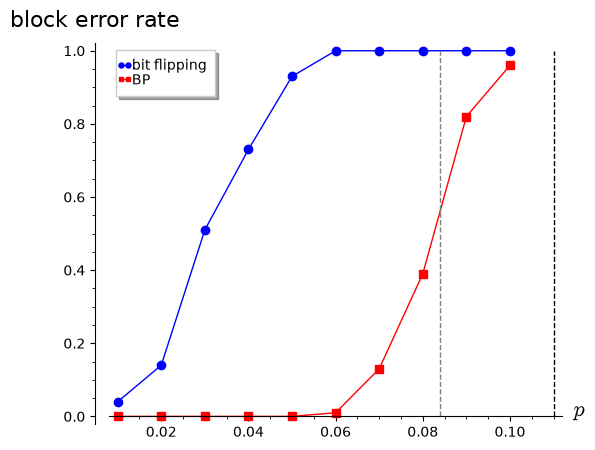

In [22]:
(line([(p, bf / 100) for p, bf, _ in results], marker="o", legend_label="bit flipping")
 + line([(p, bp / 100) for p, _, bp in results], marker="s", color="red", legend_label="BP")
 + line([(0.084, 0), (0.084, 1)], color="gray", linestyle="--")
 + line([(p_cap, 0), (p_cap, 1)], color="black", linestyle="--")
 ).show(axes_labels=[r"$p$", "block error rate"], figsize=6)

Bit flipping 在 $p = 0.03$ 時已經有一半的 blocks 失敗，  
BP 到 $p = 0.06$ 才偶爾失敗，$p = 0.08$ 時約四成。  
長度增加時，BP 的曲線會越來越陡，逼近 threshold $0.084$；  
它和 capacity $0.110$ 之間的距離，  
同樣要靠 irregular degrees 來縮小。

## 應用

### Lifting 與 base graph

實際使用的 LDPC codes 不是完全隨機的。  
先設計一個只有幾十個 nodes 的小 Tanner graph，  
稱為 **base graph**（或 protograph），  
把它複製 $Z$ 份，每條邊換成 $Z$ 條，  
第 $i$ 份的 VN 連到第 $i + s \bmod Z$ 份的 CN。  
每條邊只要記一個 shift $s$，  
而且 $Z$ 份的運算完全相同，硬體可以平行處理。

### 5G、Wi-Fi、DVB-S2

5G NR 的資料通道用兩個 base graphs：  
BG1 有 $68$ 個 VNs 與 $46$ 個 CNs，  
BG2 有 $52$ 個 VNs 與 $42$ 個 CNs。  
$Z$ 最大是 $384$，  
BG1 的一個 block 最多帶 $22 \cdot 384 = 8{,}448$ 個資訊 bits。  
Wi-Fi（802.11n 以後）的 LDPC codes  
長度是 $648$、$1{,}296$、$1{,}944$，對應 $Z = 27$、$54$、$81$。

1102 講義提過 DVB-S2：長度 $64{,}800$ 的 LDPC code 在內層，  
binary BCH code 在外層清理殘留的 errors。  
SSD 也從 BCH 換成 LDPC，  
因為讀取時可以多讀幾次電壓，得到 soft information 交給 BP。

## 延伸話題

### Irregular LDPC 與 capacity

讓 VNs 與 CNs 的 degrees 不全相同。  
令 $\lambda(x) = \sum_i\lambda_i x^{i-1}$，  
其中 $\lambda_i$ 是連到 degree $i$ 的 VN 的邊所佔的比例，  
$\rho(x)$ 對 CNs 同樣定義。  
Density evolution 變成
$$x_{\ell+1} = \epsilon\lambda\bigl(1 - \rho(1 - x_\ell)\bigr).$$

Luby–Mitzenmacher–Shokrollahi–Spielman（1997）  
找到一系列 $\lambda, \rho$，使 threshold 任意接近 capacity $1 - R$。  
在 AWGN 上，  
Chung–Forney–Richardson–Urbanke（2001）的 irregular LDPC code  
距離 Shannon limit 只有 $0.0045$ dB。

Spatially coupled LDPC codes（Kudekar–Richardson–Urbanke 2011）  
把許多 regular codes 串成一條鏈，  
BP threshold 就提升到 optimal decoder 的 threshold；  
再讓 degrees 變大，就逼近 capacity。

### Expander codes

1102 講義提到長的 BCH codes 不是 asymptotically good。  
Sipser–Spielman（1996）證明：  
若 Tanner graph 是好的 **expander**，  
也就是任何不太大的 VNs 集合都連到很多 CNs，  
則 bit flipping 能更正固定比例的 errors，而且只需要線性時間。  
用 explicit 的 expanders，  
就得到 explicit 的 asymptotically good codes。

### Error floor

雜訊很小時，LDPC 的 error rate 曲線常常變平，  
稱為 **error floor**。  
原因是小的 stopping sets 或 trapping sets：  
少數 bits 組成的結構讓 BP 卡住，和 minimum distance 無關。  
DVB-S2 外層的 BCH code 就是用來清理這些殘留的 errors。

## 週五作業

### 週一作業

#### Expander codes 達到 BSC capacity

1109 講義的 density evolution 追蹤 erasure 與 error 的機率，  
BP 追蹤的則是 LLR 的分布。  
這份作業追蹤的是「有錯的 vertices 有幾個」，  
並用 expander 的性質取代獨立性。  
結果是只用 hard decisions 的 codes，  
在 BSC 上達到 capacity（Barg–Zémor 2002）。

令 $G$ 是二部圖，兩邊的 vertices 集合 $V_1$、$V_2$ 各有 $m$ 個，  
每個 vertex 的 degree 都是 $\Delta$，共有 $N = m\Delta$ 條邊。  
每條邊放一個 bit；  
對 vertex $v$，令 $x|_v$ 是 $v$ 的 $\Delta$ 條邊上的 bits。

取兩個長度 $\Delta$ 的 binary linear codes $A$ 與 $B$，  
rate 分別是 $R_A$ 與 $R_B$，relative distance 都至少是 $\delta$。  
定義長度 $N$ 的 code
$$\mathcal C = \{x \in \mathbb F_2^N : x|_v \in A\text{ for }v \in V_1,
\ x|_v \in B\text{ for }v \in V_2\}.$$

這是 Tanner graph 的推廣：  
每個 vertex 不只是一個 parity check，而是一整個 code。

1. 證明 $\mathcal C$ 的 rate 至少是 $R_A + R_B - 1$。
2. 取 $G$ 為完全二部圖 $K_{n,n}$，也就是 $m = \Delta = n$，並取 $A = B$。  
   證明 $\mathcal C$ 就是 1109 講義的 product code $A \otimes A$：  
   邊 $(a, b)$ 對應矩陣的 entry $(a, b)$，  
   正如 1109 講義用 $K_{3,4}$ 的邊表示 $3 \times 4$ 矩陣的 entries。

以下事實不用證明。  
令 $M$ 是 $G$ 的 $m \times m$ biadjacency matrix，  
它最大的 singular value 是 $\Delta$，第二大的記為 $\lambda$。  
對任意 $S \subseteq V_1$、$T \subseteq V_2$，令 $e(S, T)$ 是兩者之間的邊數，則
$$\Bigl|e(S, T) - \frac{\Delta}{m}|S||T|\Bigr| \le \lambda\sqrt{|S||T|}.$$

這叫做 **expander mixing lemma**：  
$\lambda$ 越小，$S$ 與 $T$ 之間的邊數越接近隨機圖的期望值。  
對每個 $\Delta$，都存在任意大的 $m$ 與 $\lambda \le 2\sqrt\Delta$ 的這種圖，  
稱為 **expander**；這也不用證明。

3. 證明 $K_{n,n}$ 的 $\lambda = 0$，並寫出此時的 $e(S, T)$。  
   $K_{n,n}$ 是最好的 expander，但它的 $\Delta = n$ 會隨長度變大；  
   下面要的是 $\Delta$ 固定、$m \to \infty$ 的 expanders。

Decoder 輪流處理兩邊，只用 hard decisions。  
第 $0$ 步，每個左邊的 vertex  
把 $x|_v$ 換成 $A$ 中最接近它的 codeword，  
也就是 BSC 上的 ML decoding。

之後右邊、左邊輪流：  
每個 vertex 若找得到和 $x|_v$ 距離小於 $\delta\Delta/2$ 的 codeword，  
就把 $x|_v$ 換成它；找不到就不動。

4. 令 $S$ 是某一步之後 $x|_v$ 仍然有錯的左邊 vertices，  
   $T$ 是下一步之後 $x|_v$ 仍然有錯的右邊 vertices。  
   證明 $T$ 的每個 vertex 至少有 $\delta\Delta/2$ 條邊連到 $S$，  
   再由 mixing lemma 推出：若 $|S| < \delta m/2$，則
   $$|T| \le \Bigl(\frac{\lambda}{\Delta(\delta/2 - |S|/m)}\Bigr)^2 |S|.$$

5. 設 $\lambda \le 2\sqrt\Delta$ 而且 $|S| \le \delta m/4$，  
   證明 $|T| \le \frac{64}{\delta^2\Delta}|S|$。  
   所以 $\Delta > 128/\delta^2$ 時，每一步之後有錯的 vertices 至少減半，  
   從右邊到左邊的那一步也一樣。  
   推出：只要第 $0$ 步之後有錯的左邊 vertices 不超過 $\delta m/4$ 個，  
   $O(\log m)$ 步之後就完全沒有錯。

6. 在 $\operatorname{BSC}(p)$ 上，令 $P_A$ 是 $A$ 的 ML decoding 的錯誤機率。  
   說明第 $0$ 步各個左邊 vertex 是否解錯，為什麼彼此獨立。  
   已知 Hoeffding 不等式：$X$ 是 $m$ 個獨立的 Bernoulli$(q)$ 的和時，  
   $\Pr(X \ge (q + t)m) \le e^{-2mt^2}$。  
   證明 $P_A < \delta/4$ 時，  
   第 $0$ 步之後有錯的左邊 vertices 超過 $\delta m/4$ 個的機率隨 $m$ 指數下降。

7. 以下 Shannon 的結果不用證明：  
   對任意 $r < 1 - h(p)$，存在 rate 至少 $r$ 的長度 $\Delta$ 的 codes，  
   它們的 ML decoding 錯誤機率在 $\Delta \to \infty$ 時趨近 $0$，  
   而且 relative distance 有一個和 $\Delta$ 無關的正下界。  
   對任意 $\epsilon > 0$，說明怎麼依序選 $A$、$B$、$\delta$、$\Delta$，  
   使 $\mathcal C$ 的 rate 至少是 $1 - h(p) - \epsilon$，  
   而且 $m \to \infty$ 時 block error probability 趨近 $0$。

8. 我們已經看過三種 density evolution：  
   1109 講義的 BEC 與 SPC 追蹤 erasure 的機率，  
   BSC 與 Hamming codes 追蹤 error 的機率，  
   今天的 BP 追蹤 LLR 的分布。  
   這份作業追蹤的是什麼？  
   講義的遞迴靠乘積結構或樹得到獨立性，這裡用什麼代替？

額外練習不用交：  
每一步只需要處理上一步有錯的 vertices 的鄰居，  
所以總工作量是 $O(m)$。  
但要逼近 capacity，$\Delta$ 必須隨 $1/\epsilon$ 變大，  
而第 $0$ 步的 ML decoding 要比較 $2^{R_A\Delta}$ 個 codewords。  
估計總工作量怎麼隨 $\epsilon$ 變化。